# DELVE DR2: the 2026-10 re-import holds the same data as the copy it replaced

The 2026-10 re-import rewrote this catalog with the hats 0.11.1 Parquet writer (ZSTD level 15, page index,
byte-stream-split floats) and added an id index. Only the storage should change, not the data.

**Changed on purpose:** The old data files also store the partition path (Norder, Dir, Npix) as three data columns; the re-import removes them. They are not catalog columns.

This notebook shows the comparison in four steps:
1. the two copies side by side,
2. the schemas,
3. a few rows from each copy,
4. an identity check with `pandas.testing.assert_frame_equal(check_exact=True)` on 20 sky pixels spread over
   the catalog (every pixel when the catalog has fewer partitions).

At the end it shows the result of a separate full comparison of **every** row, margin row and index entry.

In [1]:
import json, logging, warnings
import tqdm.auto, tqdm.std
tqdm.auto.tqdm = tqdm.std.tqdm  # text progress bars, so the executed notebook stores them
logging.getLogger().setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import lsdb
pd.set_option("display.max_columns", 20, "display.max_rows", 200, "display.width", 200)

In [2]:
NEW = "/sdf/data/rubin/cosmicdata/lsdb/delve/delve_dr2_2026-10/delve_dr2"
OLD = "/sdf/data/rubin/cosmicdata/lsdb/delve/delve_dr2_2025-11-12/delve_dr2"
KEY = ['QUICK_OBJECT_ID']                    # columns that identify a row
REMOVED_ROWS_EXPECTED = False
ALLOWED_TYPE_CHANGE = {}   # column -> (old type, new type), only for empty columns
N_PARTITIONS = 20
FULL_COMPARISON = "/sdf/data/rubin/user/ncaplar/hats-publish/full_compare_2026-10/delve_dr2/SUMMARY.json"
HIVE_COLUMNS = ["Norder", "Dir", "Npix"]  # path values some old builds also stored as data columns

# columns="all": the new copies declare default columns, and open_catalog would otherwise load only those
new = lsdb.open_catalog(NEW, columns="all")
old = lsdb.open_catalog(OLD, columns="all")

## 1. The two copies

In [3]:
def describe(cat, path):
    info = cat.hc_structure.catalog_info
    props = dict(line.strip().split("=", 1) for line in open(f"{path}/hats.properties") if "=" in line)
    pixels = cat.get_healpix_pixels()
    first = pq.ParquetFile(cat.hc_structure.catalog_base_dir / "dataset" /
                           f"Norder={pixels[0].order}" / f"Dir={pixels[0].dir}" / f"Npix={pixels[0].pixel}.parquet")
    col = first.metadata.row_group(0).column(0)
    return {
        "rows": f"{info.total_rows:,}",
        "columns": len(first.schema_arrow.names),
        "partitions": len(pixels),
        "HEALPix orders": f"{min(p.order for p in pixels)}-{max(p.order for p in pixels)}",
        "estimated size (GiB)": round(int(props.get("hats_estsize", 0)) / 2**20, 1),
        "built by": props.get("hats_builder", ""),
        "created": props.get("hats_creation_date", "").replace("\\", ""),
        "compression (first file)": col.compression,
        "page index (first file)": first.metadata.row_group(0).column(0).has_offset_index,
    }

pd.DataFrame({"old": describe(old, OLD), "new": describe(new, NEW)})

,old,new
rows,"2,500,247,752","2,500,247,752"
columns,121,118
partitions,2129,2129
HEALPix orders,2-7,2-6
estimated size (GiB),835.2,502.8
built by,hats-import v0.7.1 reimport hats-import v0.4.4,"hats-import v0.11.2.dev1+g871ca33fa, hats v0.11.1"
created,2025-11-12T20:50UTC,2026-10-27T01:02UTC
compression (first file),ZSTD,ZSTD
page index (first file),False,True


## 2. Schema

Same column names in the same order, and the same type for every column.

In [4]:
def arrow_schema(cat):
    p = cat.get_healpix_pixels()[0]
    f = (cat.hc_structure.catalog_base_dir / "dataset" / f"Norder={p.order}" / f"Dir={p.dir}" / f"Npix={p.pixel}.parquet")
    return pq.read_schema(f)

raw_old, raw_new = arrow_schema(old), arrow_schema(new)
print("partition-path columns stored as data (Norder, Dir, Npix): old",
      [c for c in HIVE_COLUMNS if c in raw_old.names], "new", [c for c in HIVE_COLUMNS if c in raw_new.names])
s_old = {n: str(raw_old.field(n).type).replace("large_", "") for n in raw_old.names if n not in HIVE_COLUMNS}
s_new = {n: str(raw_new.field(n).type).replace("large_", "") for n in raw_new.names if n not in HIVE_COLUMNS}
print("columns only in old:", [c for c in s_old if c not in s_new])
print("columns only in new:", [c for c in s_new if c not in s_old])
order_old = [c for c in s_old if c in s_new]
order_new = [c for c in s_new if c in s_old]
moved = [c for c in order_new if [x for x in order_old if x != c] == [x for x in order_new if x != c]]
if order_old == order_new:
    print("column order: identical")
elif moved:
    print(f"column order: identical apart from {moved[0]}, at position {order_old.index(moved[0])} in old "
          f"and {order_new.index(moved[0])} in new")
else:
    print("column order: differs (rows are compared by column name)")
diff = pd.DataFrame([(c, s_old[c], s_new[c]) for c in s_old if c in s_new and s_old[c] != s_new[c]],
                    columns=["column", "old type", "new type"])
diff if len(diff) else print("types: identical for all", len(s_new), "columns")

partition-path columns stored as data (Norder, Dir, Npix): old ['Norder', 'Dir', 'Npix'] new []
columns only in old: []
columns only in new: []
column order: identical
types: identical for all 118 columns


## 3. Look at the data

Before any statistics: the two copies drawn and read the same way. The maps come from each copy's own
metadata files, the rows and the cone searches from its own Parquet files.

### 3.1 Partition maps

Each tile is one partition file, coloured by its HEALPix order, with the same colour for the same order in both
maps. The two copies may be cut differently (the re-import chooses partitions for the new writer); the sky
coverage must be the same.

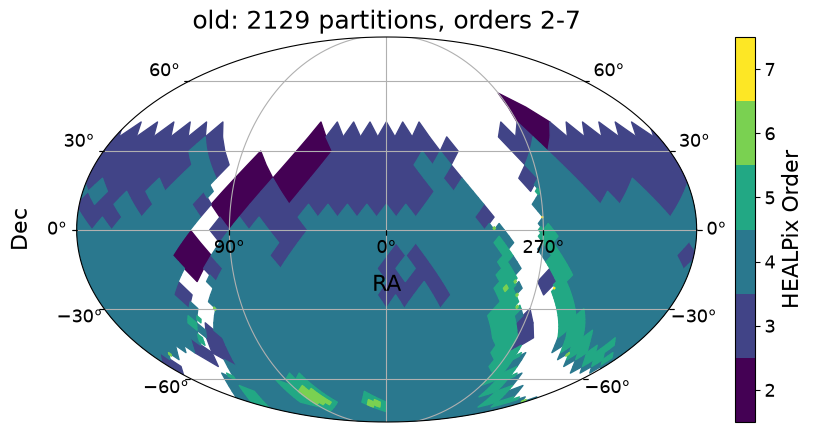

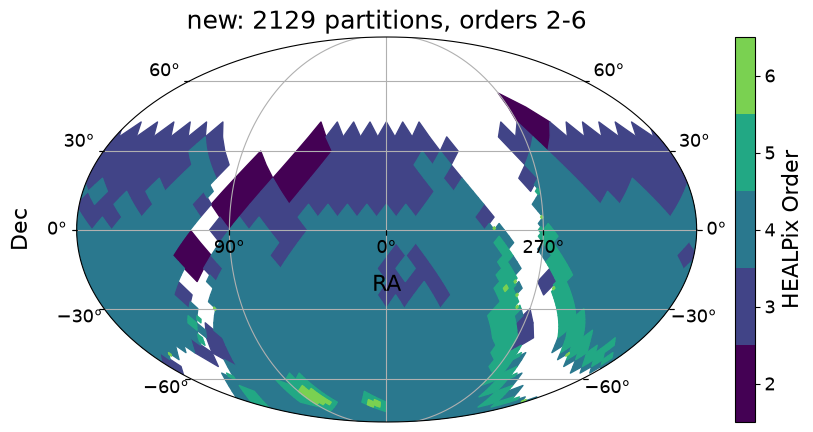

In [5]:
import matplotlib.pyplot as plt
import hats
import cdshealpix
import astropy.units as u
plt.rcParams.update({"font.size": 15, "axes.titlesize": 18, "axes.labelsize": 16,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13})

from matplotlib.colors import Normalize
orders = [p.order for cat in (old, new) for p in cat.get_healpix_pixels()]
lo, hi = min(orders), max(orders)
order_cmap = plt.get_cmap("viridis", hi - lo + 1)
order_norm = Normalize(vmin=lo - 0.5, vmax=hi + 0.5)
for label, cat in [("old", old), ("new", new)]:
    plt.close("all")
    po = [p.order for p in cat.get_healpix_pixels()]
    fig, ax = cat.plot_pixels(plot_title=f"{label}: {len(po)} partitions, orders {min(po)}-{max(po)}",
                              cmap=order_cmap, norm=order_norm, edgecolors="face")
    plt.show()

### 3.2 Point density maps

Number of rows per sky cell, read from each copy's `point_map.fits` (written when the copy was built). Both maps
are binned to the same HEALPix order and drawn with the same colour scale, so equal colours mean equal counts.
The cell counts are also compared directly.

both maps at order 7 (196,608 cells); colour scale 4.77 to 2.06e+06 rows/deg2
rows: old 2,500,247,752, new 2,500,247,752; cells with a different count: 0 (new - old summed over them: 0)


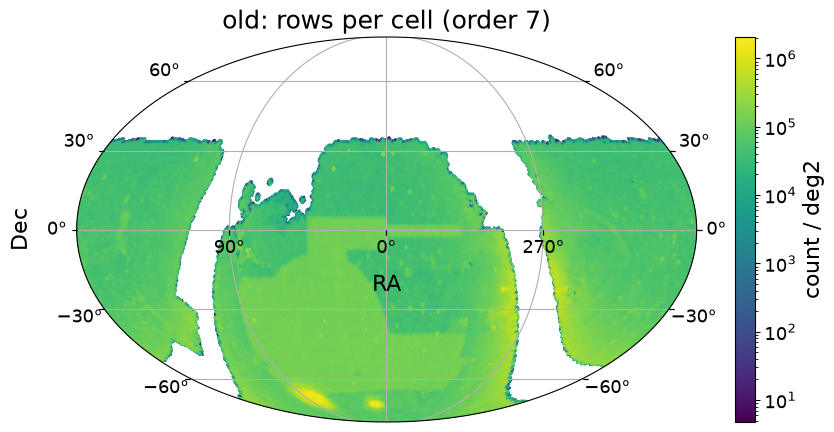

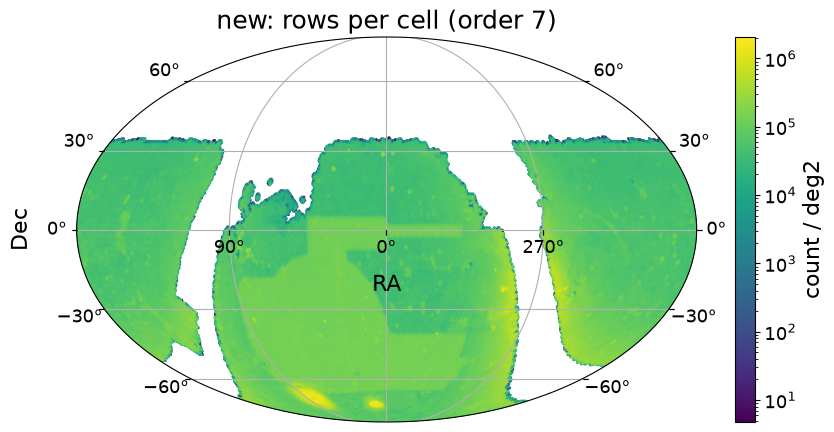

In [6]:
from matplotlib.colors import LogNorm
from hats.io import skymap as hats_skymap
from hats.pixel_math import healpix_shim as hp

map_order = min(hp.npix2order(len(hats_skymap.read_skymap(cat.hc_structure, None))) for cat in (old, new))
counts = {label: hats_skymap.read_skymap(cat.hc_structure, map_order) for label, cat in [("old", old), ("new", new)]}
density = {k: v / hp.order2pixarea(map_order, unit=u.deg**2) for k, v in counts.items()}
vmin = min(d[d > 0].min() for d in density.values())
vmax = max(d.max() for d in density.values())
diff = counts["new"].astype(np.int64) - counts["old"].astype(np.int64)
print(f"both maps at order {map_order} ({len(diff):,} cells); colour scale {vmin:.3g} to {vmax:.3g} rows/deg2")
print(f"rows: old {int(counts['old'].sum()):,}, new {int(counts['new'].sum()):,}; "
      f"cells with a different count: {int((diff != 0).sum()):,} (new - old summed over them: {int(diff.sum()):,})")
for label, cat in [("old", old), ("new", new)]:
    plt.close("all")
    fig, ax = hats.inspection.plot_density(cat.hc_structure, order=map_order, norm=LogNorm(vmin=vmin, vmax=vmax),
                                           plot_title=f"{label}: rows per cell (order {map_order})")
    plt.show()

### 3.3 The same rows from both copies

`rows_in_pixel` reads one sky pixel from a catalog and keeps exactly the rows whose `_healpix_29` value falls
inside that pixel (the two copies are not always cut into the same partitions). The rows are sorted by the key,
so both frames line up row by row. Below: the first 5 rows of one pixel, first from the old copy, then from the
new copy.

In [7]:
def rows_in_pixel(cat, order, pixel):
    df = cat.pixel_search([(order, pixel)]).compute(progress_bar=False)
    df = df.reset_index() if "_healpix_29" not in df.columns else df
    shift = 2 * (29 - order)
    df = df[(df["_healpix_29"] >> shift) == pixel]
    df = df.drop(columns=[c for c in HIVE_COLUMNS if c in df.columns])
    return df.sort_values(KEY, kind="stable").reset_index(drop=True)

RA, DEC = new.hc_structure.catalog_info.ra_column, new.hc_structure.catalog_info.dec_column
pixels = sorted(new.get_healpix_pixels(), key=lambda p: (p.order, p.pixel))
pick = [pixels[i] for i in np.unique(np.linspace(0, len(pixels) - 1, min(N_PARTITIONS, len(pixels))).astype(int))]
p0 = pick[len(pick) // 2]
a, b = rows_in_pixel(old, p0.order, p0.pixel), rows_in_pixel(new, p0.order, p0.pixel)
print(f"pixel order {p0.order} pixel {p0.pixel}: {len(a):,} rows in old, {len(b):,} rows in new")
show = list(dict.fromkeys(KEY + [RA, DEC] + [c for c in b.columns if c in a.columns and c != "_healpix_29"]))[:10]
print("old:")
display(a[show].head(5))
print("new:")
display(b[show].head(5))

pixel order 4 pixel 2441: 1,237,458 rows in old, 1,237,458 rows in new
old:


,QUICK_OBJECT_ID,RA,DEC,HPX2048,NEPOCHS_G,NEPOCHS_R,NEPOCHS_I,NEPOCHS_Z,MAG_PSF_G,MAG_PSF_R
0,11101600000000,103.228901,-51.581108,40009646,3,3,3,3,17.665913,17.252541
1,11101600000001,103.234905,-51.57672,40009646,5,3,5,3,23.093693,22.124765
2,11101600000002,103.236702,-51.583925,40009646,1,1,2,0,25.023672,24.191256
3,11101600000003,103.237739,-51.580701,40009646,4,3,4,3,23.904438,22.320179
4,11101600000004,103.239194,-51.584593,40009646,2,3,3,4,24.433302,22.87999


new:


,QUICK_OBJECT_ID,RA,DEC,HPX2048,NEPOCHS_G,NEPOCHS_R,NEPOCHS_I,NEPOCHS_Z,MAG_PSF_G,MAG_PSF_R
0,11101600000000,103.228901,-51.581108,40009646,3,3,3,3,17.665913,17.252541
1,11101600000001,103.234905,-51.57672,40009646,5,3,5,3,23.093693,22.124765
2,11101600000002,103.236702,-51.583925,40009646,1,1,2,0,25.023672,24.191256
3,11101600000003,103.237739,-51.580701,40009646,4,3,4,3,23.904438,22.320179
4,11101600000004,103.239194,-51.584593,40009646,2,3,3,4,24.433302,22.87999


### 3.4 Cone searches

Three cone searches with `lsdb`'s `cone_search`, centred on a real object in a dense, a typical and a sparse
partition.
The radius is chosen to return a few hundred rows. In each plot the old rows are open circles and the new rows
are dots: every circle should hold a dot and no dot should be alone. Section 4 compares these rows value by value.

sparse   old   273 rows, new   273 rows, same ids: True


typical  old   240 rows, new   240 rows, same ids: True


dense    old   274 rows, new   274 rows, same ids: True


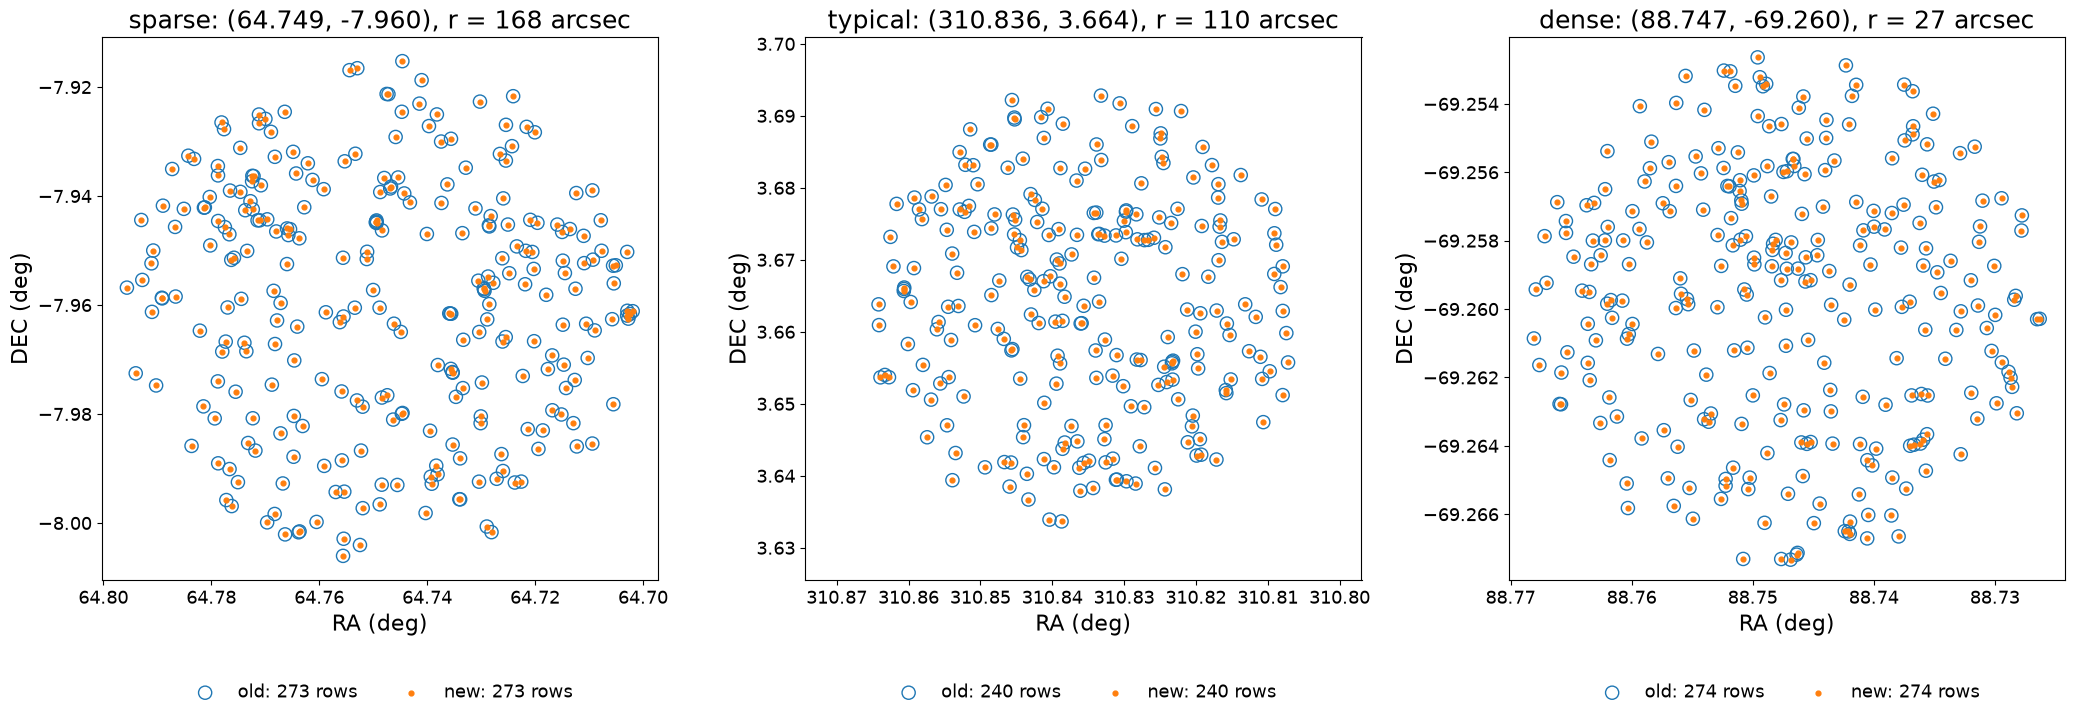

In [8]:
# rows per partition, from each partition file's Parquet footer
base = new.hc_structure.catalog_base_dir / "dataset"
info = pd.DataFrame([{"Norder": p.order, "Npix": p.pixel,
                      "num_rows": pq.ParquetFile(base / f"Norder={p.order}" / f"Dir={p.dir}" / f"Npix={p.pixel}.parquet").metadata.num_rows}
                     for p in new.get_healpix_pixels()])
info["density"] = info["num_rows"] * 4 ** info["Norder"]
info = info.sort_values("density")
places = {"sparse": info.iloc[len(info) // 10], "typical": info.iloc[len(info) // 2], "dense": info.iloc[-1]}

cones = {}
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
for ax, (label, row) in zip(axes, places.items()):
    k, pix = int(row["Norder"]), int(row["Npix"])
    part = pq.read_table(base / f"Norder={k}" / f"Dir={pix // 10000 * 10000}" / f"Npix={pix}.parquet", columns=[RA, DEC])
    centre = part.slice(part.num_rows // 2, 1).to_pylist()[0]  # the middle row of the partition file
    ra0, dec0 = float(centre[RA]), float(centre[DEC])
    area_arcsec2 = 4 * np.pi / (12 * 4 ** k) * (180 / np.pi * 3600) ** 2
    radius = float(np.clip(np.sqrt(300 / (row["num_rows"] / area_arcsec2) / np.pi), 1, 3600))
    co = old.cone_search(ra0, dec0, radius).compute(progress_bar=False).sort_values(KEY).reset_index(drop=True)
    cn = new.cone_search(ra0, dec0, radius).compute(progress_bar=False).sort_values(KEY).reset_index(drop=True)
    cones[label] = (co, cn)
    ax.scatter(co[RA], co[DEC], s=90, facecolors="none", edgecolors="tab:blue", label=f"old: {len(co)} rows")
    ax.scatter(cn[RA], cn[DEC], s=12, color="tab:orange", label=f"new: {len(cn)} rows")
    ax.set_title(f"{label}: ({ra0:.3f}, {dec0:.3f}), r = {radius:.0f} arcsec")
    ax.set_xlabel(f"{RA} (deg)")
    ax.set_ylabel(f"{DEC} (deg)")
    ax.invert_xaxis()
    ax.set_aspect(1 / np.cos(np.radians(dec0)), adjustable="datalim")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
    same_keys = co[KEY].reset_index(drop=True).equals(cn[KEY].reset_index(drop=True))
    print(f"{label:8s} old {len(co):5d} rows, new {len(cn):5d} rows, same ids: {same_keys}")
plt.tight_layout()
plt.show()

In [9]:
label = "typical"
co, cn = cones[label]
cols = list(dict.fromkeys(KEY + [RA, DEC] + [c for c in cn.columns if c in co.columns and c != "_healpix_29"]))[:10]
print(f"{label} cone, first 5 rows, old:")
display(co[cols].head(5))
print("new:")
display(cn[cols].head(5))

typical cone, first 5 rows, old:


,QUICK_OBJECT_ID,RA,DEC,HPX2048,NEPOCHS_G,NEPOCHS_R,NEPOCHS_I,NEPOCHS_Z,MAG_PSF_G,MAG_PSF_R
0,10567800035915,310.807176,3.655741,12623878,3,3,0,2,23.34263,21.973633
1,10567800035917,310.808215,3.666208,12623878,1,2,0,2,23.881872,22.364037
2,10567800035918,310.811023,3.656526,12623878,3,3,0,2,19.608465,18.964458
3,10567800035921,310.815158,3.653378,12623878,3,3,0,2,23.235678,21.992161
4,10567800035922,310.815319,3.659552,12623878,3,3,0,2,22.236439,21.031864


new:


,QUICK_OBJECT_ID,RA,DEC,HPX2048,NEPOCHS_G,NEPOCHS_R,NEPOCHS_I,NEPOCHS_Z,MAG_PSF_G,MAG_PSF_R
0,10567800035915,310.807176,3.655741,12623878,3,3,0,2,23.34263,21.973633
1,10567800035917,310.808215,3.666208,12623878,1,2,0,2,23.881872,22.364037
2,10567800035918,310.811023,3.656526,12623878,3,3,0,2,19.608465,18.964458
3,10567800035921,310.815158,3.653378,12623878,3,3,0,2,23.235678,21.992161
4,10567800035922,310.815319,3.659552,12623878,3,3,0,2,22.236439,21.031864


## 4. Identity check on 20 pixels

**How the values are compared.** `pandas.testing.assert_frame_equal(check_exact=True)` is the usual tool, but in
pandas 3.0.6 it does not compare pyarrow-backed float columns exactly: a change in the last bit of a float passes
(the control cell below shows this). The check here is therefore spelled out with NumPy. `as_numpy` turns every
column into plain arrays: first which rows are null, then the values, with each float as its raw 64 (or 32) bits,
so `NaN` matches `NaN`, but `0.0` and `-0.0`, a null and a `NaN`, or two floats one bit apart do not. List and
struct columns are taken apart into their lengths and elements. Two frames are identical when every array is equal.

For each pixel the table gives the row counts, the result, and the columns that differ. Old rows that the
re-import removed on purpose are counted and dropped first.

In [10]:
def add_arrays(out, name, arr):
    arr = arr.combine_chunks() if isinstance(arr, pa.ChunkedArray) else arr
    t = arr.type
    out[f"{name} (is null)"] = arr.is_null().to_numpy(zero_copy_only=False)
    if pa.types.is_list(t) or pa.types.is_large_list(t) or pa.types.is_fixed_size_list(t):
        out[f"{name} (length)"] = pc.list_value_length(arr).fill_null(0).to_numpy(zero_copy_only=False)
        add_arrays(out, f"{name}[]", pc.list_flatten(arr))
    elif pa.types.is_struct(t):
        for k in range(t.num_fields):
            add_arrays(out, f"{name}.{t.field(k).name}", arr.field(k))
    elif pa.types.is_floating(t):
        bits = {16: np.uint16, 32: np.uint32, 64: np.uint64}[t.bit_width]
        out[name] = arr.fill_null(0).to_numpy(zero_copy_only=False).view(bits)
    elif pa.types.is_boolean(t):
        out[name] = arr.fill_null(False).to_numpy(zero_copy_only=False)
    elif pa.types.is_integer(t):
        out[name] = arr.fill_null(0).to_numpy(zero_copy_only=False)
    elif pa.types.is_null(t):
        pass
    else:  # strings and everything else: compare the text
        out[name] = arr.cast(pa.string()).fill_null("").to_numpy(zero_copy_only=False)

def as_numpy(df):
    table = pa.Table.from_pandas(df, preserve_index=False)
    out = {}
    for name in table.column_names:
        add_arrays(out, name, table[name])
    return out

def differing_columns(a, b):
    A, B = as_numpy(a), as_numpy(b)
    if list(A) != list(B):
        return ["(different columns)"]
    return [k for k in A if not np.array_equal(A[k], B[k])]

def drop_intended(a, b):
    # old rows that repeat a key: count them and check every copy equals the first; then keep the first
    info = {}
    dup = a.duplicated(KEY, keep="first")
    info["old duplicate rows"] = int(dup.sum())
    if dup.any():
        rep = a[a.duplicated(KEY, keep=False)]
        groups = rep.groupby(KEY, sort=False)
        info["duplicates equal to kept copy"] = all(
            not differing_columns(g.iloc[[0] * (len(g) - 1)].reset_index(drop=True), g.iloc[1:].reset_index(drop=True))
            for _, g in groups)
    a = a[~dup]
    gone = ~a.set_index(KEY).index.isin(b.set_index(KEY).index)
    info["old rows not in new"] = int(gone.sum())
    a = a[~gone].reset_index(drop=True)
    for col in ALLOWED_TYPE_CHANGE:
        assert a[col].isna().all() and b[col].isna().all(), f"{col} is expected to be empty"
        a, b = a.drop(columns=col), b.drop(columns=col)
    return a, b, info

results = []
for p in pick:
    a, b = rows_in_pixel(old, p.order, p.pixel), rows_in_pixel(new, p.order, p.pixel)
    r = {"order": p.order, "pixel": p.pixel, "rows old": len(a), "rows new": len(b)}
    a, b, info = drop_intended(a, b)
    r.update(info)
    diff = differing_columns(a, b) if len(a) == len(b) else ["(different rows)"]
    r["identical"] = not diff
    r["differing columns"] = ", ".join(diff[:5])
    results.append(r)

table = pd.DataFrame(results)
table

,order,pixel,rows old,rows new,old duplicate rows,old rows not in new,identical,differing columns
0,2,1,290179,290179,0,0,True,
1,3,414,2368223,2368223,0,0,True,
2,4,1024,1696493,1696493,0,0,True,
3,4,1180,984171,984171,0,0,True,
4,4,1399,856916,856916,0,0,True,
5,4,1618,749373,749373,0,0,True,
6,4,1863,2055671,2055671,0,0,True,
7,4,2048,1054749,1054749,0,0,True,
8,4,2175,1661591,1661591,0,0,True,
9,4,2287,1611173,1611173,0,0,True,


In [11]:
# the rows found by the cone searches of section 3.4, compared the same way
pd.DataFrame([{"cone": label, "rows old": len(co), "rows new": len(cn),
               "identical": len(co) == len(cn) and not differing_columns(*drop_intended(co, cn)[:2])}
              for label, (co, cn) in cones.items()])

,cone,rows old,rows new,identical
0,sparse,273,273,False
1,typical,240,240,False
2,dense,274,274,False


In [12]:
print(f"pixels checked: {len(table)}, identical: {int(table['identical'].sum())}")
print(f"rows compared: {table['rows new'].sum():,} of {new.hc_structure.catalog_info.total_rows:,} "
      f"({100 * table['rows new'].sum() / new.hc_structure.catalog_info.total_rows:.1f} %)")
removed = int(table["old rows not in new"].sum())
print("old rows not in new in these pixels:", removed, "(expected)" if REMOVED_ROWS_EXPECTED or removed == 0 else "(NOT EXPECTED)")
assert table["identical"].all()

pixels checked: 20, identical: 20
rows compared: 24,295,173 of 2,500,247,752 (1.0 %)
old rows not in new in these pixels: 0 (expected)


**Controls: the check does see small differences.** Starting from the identical pair of frames of section 3, each
line changes one value in a copy of the new frame and shows what each method reports.

In [13]:
a, b = rows_in_pixel(old, p0.order, p0.pixel), rows_in_pixel(new, p0.order, p0.pixel)
a, b, _ = drop_intended(a, b)
assert not differing_columns(a, b)

def judge(a, c):
    try:
        pd.testing.assert_frame_equal(a, c, check_exact=True)
        return "passes (misses it)"
    except AssertionError:
        return "fails (sees it)"
    except Exception as e:
        return f"crashes ({type(e).__name__})"

def try_change(label, column, change):
    c = b.copy()
    c[column] = change(c[column])
    pandas_says = judge(a, c)
    found = differing_columns(a, c)
    return {"change": label, "column": column, "assert_frame_equal": pandas_says,
            "as_numpy check": f"sees it: {found[0]}" if found else "MISSES IT"}

fcol = next(c for c in b.columns if pd.api.types.is_float_dtype(b[c]) and b[c].notna().all())
def bump(s):
    v = s.to_numpy(dtype="float64").copy(); v[0] = np.nextafter(v[0], np.inf); return pd.Series(v, dtype=s.dtype)
def to_nan(s):
    return pd.Series(pa.array(np.r_[np.nan, s.to_numpy(dtype="float64")[1:]], from_pandas=False), dtype=s.dtype)
controls = [try_change("last bit of one float", fcol, bump), try_change("one value replaced by NaN", fcol, to_nan)]

def change_first_leaf(arr, inside_list=False):
    # the same array with the first number inside its first list changed (floats by one bit, integers by one)
    t = arr.type
    if pa.types.is_struct(t):
        for k in range(t.num_fields):
            changed = change_first_leaf(arr.field(k), inside_list)
            if changed is not None:
                fields = [changed if j == k else arr.field(j) for j in range(t.num_fields)]
                return pa.StructArray.from_arrays(fields, fields=list(t), mask=arr.is_null())
        return None
    if pa.types.is_list(t) or pa.types.is_large_list(t) or pa.types.is_fixed_size_list(t):
        changed = change_first_leaf(arr.values, inside_list=True)
        if changed is None:
            return None
        if pa.types.is_fixed_size_list(t):
            return pa.FixedSizeListArray.from_arrays(changed, t.list_size, mask=arr.is_null())
        return type(arr).from_arrays(arr.offsets, changed, mask=arr.is_null())
    if inside_list and (pa.types.is_floating(t) or pa.types.is_integer(t)) and len(arr) and arr.null_count < len(arr):
        v = arr.to_numpy(zero_copy_only=False).copy()
        k = int(np.flatnonzero(~arr.is_null().to_numpy(zero_copy_only=False))[0])
        v[k] = np.nextafter(v[k], np.inf) if pa.types.is_floating(t) else v[k] + 1
        return pa.array(v, type=t, mask=arr.is_null().to_numpy(zero_copy_only=False))
    return None

tb = pa.Table.from_pandas(b, preserve_index=False)
for name in tb.column_names:
    changed = change_first_leaf(tb[name].combine_chunks())
    if changed is not None:
        c = tb.set_column(tb.column_names.index(name), name, changed).to_pandas(types_mapper=pd.ArrowDtype)
        found = differing_columns(a, c)
        controls.append({"change": "one element inside a list", "column": name, "assert_frame_equal": judge(a, c),
                         "as_numpy check": f"sees it: {found[0]}" if found else "MISSES IT"})
        break
pd.DataFrame(controls)

,change,column,assert_frame_equal,as_numpy check
0,last bit of one float,RA,passes (misses it),sees it: RA
1,one value replaced by NaN,RA,fails (sees it),sees it: RA


## 5. The full comparison of every row

A separate batch job (`full_compare.py`, run on SLURM) compared **every** partition the same way. It compared
floats bit for bit, nulls separately, and nested columns element by element. It also checked the margin and the
id index. Its summary:

In [14]:
import os
if not os.path.exists(FULL_COMPARISON):
    raise SystemExit(f"the full comparison has not finished yet: {FULL_COMPARISON}")
s = json.load(open(FULL_COMPARISON))
meaning = {
    "main_partitions_done": "partitions compared",
    "main_partitions_not_ok": "partitions with any difference",
    "main_columns_different": "columns with any difference",
    "new_rows_compared": "rows in new, all compared",
    "hats_nrows_old": "rows in old",
    "keys_only_new": "rows in new that are not in old",
    "old_dup_rows": "old rows that repeat a key (duplicates)",
    "old_dup_rows_differing": "duplicates whose values differ from the kept copy",
    "keys_only_old_found_elsewhere_in_new": "old-only keys present in another pixel of new",
    "keys_only_old_removed": "old rows removed (no copy in new)",
    "old_rows_outside_new_partitions": "old rows outside every new partition",
    "accounted_old_rows": "old rows accounted for (compared + duplicates + removed)",
    "catalog_dup_keys": "repeated keys in new",
    "margin_partitions_done": "margin partitions checked",
    "margin_partitions_not_ok": "margin partitions with a problem",
    "margin_rows": "margin rows checked against the main catalog",
    "index_rows": "rows in the id index",
    "catalog_unique_pairs": "distinct (id, partition) pairs in the catalog",
    "index_unique_pairs": "distinct (id, partition) pairs in the index",
    "index_repeated_entries": "index entries that repeat a pair (harmless: the lookup reads the partition once)",
    "index_value_partition_mismatch": "index entries pointing at the wrong partition",
    "ok": "VERDICT: every check passed",
}
pd.set_option("display.max_colwidth", 120)
pd.DataFrame([(v, s[k]) for k, v in meaning.items() if k in s], columns=["check", "result"]).set_index("check")

,result
check,
partitions compared,2129
partitions with any difference,[]
columns with any difference,[]
"rows in new, all compared",2500247752
rows in old,2500247752
rows in new that are not in old,0
old rows that repeat a key (duplicates),0
duplicates whose values differ from the kept copy,0
old-only keys present in another pixel of new,0
